<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/2_PyStac_NDVI_Monthly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
!pip install -q pystac-client stackstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.3 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collections in catalog.get_collections():
  print(collections.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
bbox = [67.27, 43.55, 67.38, 43.66]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = bbox,
    datetime = '2023/2025',
    query = {'eo:cloud_cover':{'lt':'10'}}
)

In [7]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [8]:
len(items)

195

In [9]:
items[0]

<Item id=S2C_T42TUP_20251222T063307_L2A>

In [10]:
import stackstac

In [11]:
ds = stackstac.stack(
    items,
    assets = ['red','rededge1','nir'],
    bounds_latlon = bbox,
    epsg = 3857,
    resolution = 20
)

In [12]:
ds_clean = ds.to_dataset('band').drop_dims('band').reset_coords(drop = True).drop_attrs()

In [13]:
ds_clean

<xarray.Dataset> Size: 2GB
Dimensions:   (time: 195, y: 846, x: 613)
Coordinates:
  * time      (time) datetime64[ns] 2kB 2023-01-12T06:37:03.258000 ... 2025-1...
  * y         (y) float64 7kB 5.413e+06 5.413e+06 ... 5.396e+06 5.396e+06
  * x         (x) float64 5kB 7.488e+06 7.488e+06 ... 7.501e+06 7.501e+06
Data variables:
    red       (time, y, x) float64 809MB dask.array<chunksize=(1, 846, 613), meta=np.ndarray>
    rededge1  (time, y, x) float64 809MB dask.array<chunksize=(1, 846, 613), meta=np.ndarray>
    nir       (time, y, x) float64 809MB dask.array<chunksize=(1, 846, 613), meta=np.ndarray>

In [14]:
nir = ds_clean['nir']
red = ds_clean['red']
rededge = ds_clean['rededge1']

In [15]:
ndvi = ((nir - red) / (nir + red)).rename('ndvi')
ndre = ((nir - rededge)/ (nir + rededge)).rename('ndre')

In [16]:
import xarray as xr

In [17]:
ds_merge = xr.merge([ndvi, ndre])

In [18]:
ds_monthly = ds_merge.resample(time = 'M').max('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


In [19]:
from dask.diagnostics import ProgressBar

In [20]:
import warnings
import logging
warnings.filterwarnings('ignore',category = RuntimeWarning)
logging.getLogger('rasterio._env').setLevel(logging.ERROR)

In [21]:
with ProgressBar():
  ds_monthly = ds_monthly.compute()

[########################################] | 100% Completed | 276.81 s


In [22]:
ds_month = ds_monthly.groupby('time.month').mean('time')

In [23]:
ds_month

<xarray.Dataset> Size: 100MB
Dimensions:  (month: 12, y: 846, x: 613)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * y        (y) float64 7kB 5.413e+06 5.413e+06 ... 5.396e+06 5.396e+06
  * x        (x) float64 5kB 7.488e+06 7.488e+06 ... 7.501e+06 7.501e+06
Data variables:
    ndvi     (month, y, x) float64 50MB 0.2083 0.2055 0.211 ... 0.1746 0.1543
    ndre     (month, y, x) float64 50MB 0.1403 0.1378 0.1799 ... 0.2605 0.1042

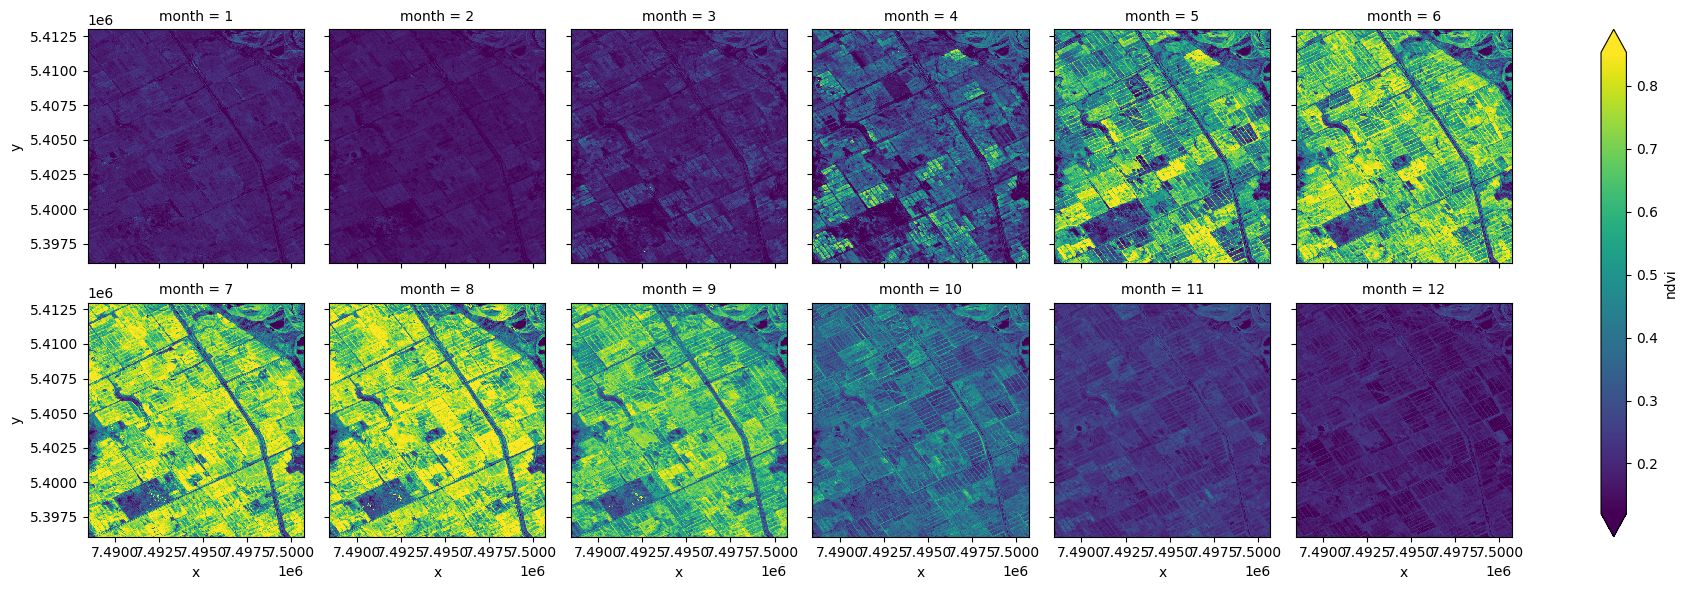

In [24]:
ds_month.ndvi.plot(
    robust = True, col = 'month', col_wrap = 6
)

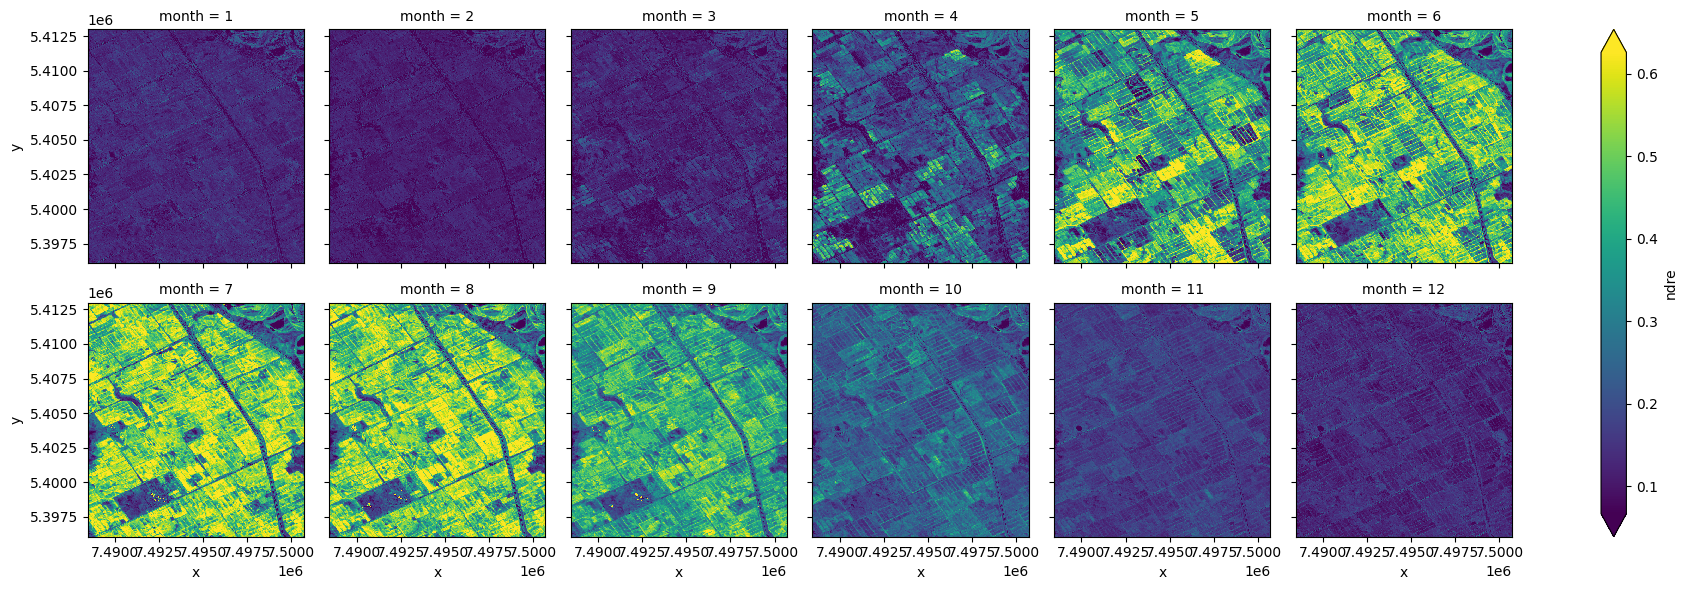

In [25]:
ds_month.ndre.plot(
    robust = True, col = 'month', col_wrap = 6
)

In [43]:
df = ds_monthly.sel(x = 67.375342, y = 43.565907, method = 'nearest').to_dataframe().drop(['x','y'], axis = 1)

<Axes: xlabel='time'>

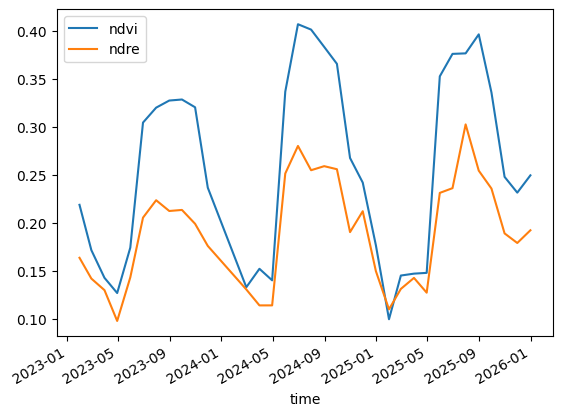

In [40]:
df[df['ndvi']<=1].plot()

<Axes: xlabel='time'>

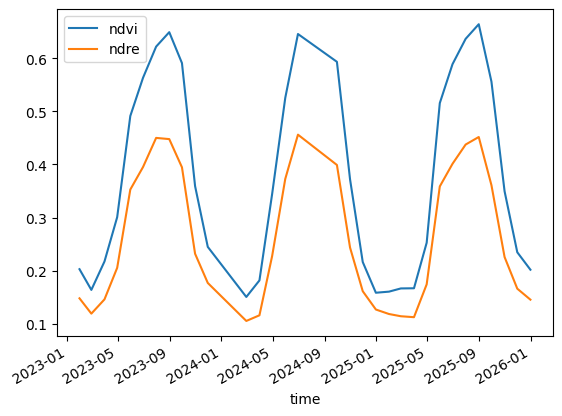

In [47]:
df2 = ds_monthly.mean(dim = ['x','y']).to_dataframe()
df2[df2['ndvi']<=1].plot()

In [48]:
!pip install -q rioxarray
import rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.7 MB/s eta 0:00:00


In [49]:
ndvi_out = ds_monthly['ndvi'].sel(time = '2024').copy()
ndvi_out = ndvi_out.rio.write_crs('EPSG:3857')
ndvi_out = ndvi_out.rio.set_spatial_dims(x_dim = 'x', y_dim = 'y')
ndvi_out = ndvi_out.rio.write_coordinate_system(inplace =True)
ndvi_out.rio.to_raster('ndvi.tiff')